In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
df=pd.read_csv('/content/household_power_consumption.txt',sep=";")
df

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0
...,...,...,...,...,...,...,...,...,...
1613982,10/1/2010,13:06:00,4.336,0.354,239.060,18.200,37.000,0.000,18.0
1613983,10/1/2010,13:07:00,4.300,0.348,238.910,18.000,38.000,0.000,18.0
1613984,10/1/2010,13:08:00,4.514,0.348,239.650,18.800,38.000,0.000,18.0
1613985,10/1/2010,13:09:00,4.668,0.348,239.850,19.400,38.000,0.000,19.0


In [3]:
df.shape

(1613987, 9)

In [4]:
df.columns

Index(['Date', 'Time', 'Global_active_power', 'Global_reactive_power',
       'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='object')

In [5]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1613987 entries, 0 to 1613986
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Date                   1613987 non-null  object 
 1   Time                   1613987 non-null  object 
 2   Global_active_power    1613987 non-null  object 
 3   Global_reactive_power  1613987 non-null  object 
 4   Voltage                1613987 non-null  object 
 5   Global_intensity       1613987 non-null  object 
 6   Sub_metering_1         1613987 non-null  object 
 7   Sub_metering_2         1613987 non-null  object 
 8   Sub_metering_3         1605635 non-null  float64
dtypes: float64(1), object(8)
memory usage: 110.8+ MB


In [7]:
df.isna().sum()

,0
Date,0
Time,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,8352


In [8]:
df['Sub_metering_3'].unique()

array([17., 16., 18.,  9.,  0.,  5., 19., 10., 20.,  8.,  4.,  2.,  3.,
       11., 13.,  6., 15., nan, 12.,  1., 14.,  7., 23., 25., 26., 28.,
       27., 21., 22., 29., 24., 30., 31.])

In [9]:
df['Sub_metering_3'] = df['Sub_metering_3'].fillna(df['Sub_metering_3'].median())

In [10]:
df['Sub_metering_3'].unique()

array([17., 16., 18.,  9.,  0.,  5., 19., 10., 20.,  8.,  4.,  2.,  3.,
       11., 13.,  6., 15.,  1., 12., 14.,  7., 23., 25., 26., 28., 27.,
       21., 22., 29., 24., 30., 31.])

In [11]:
df['Global_active_power'].unique()

array(['4.216', '5.360', '5.374', ..., '7.500', '8.154', '6.874'],
      shape=(4158,), dtype=object)

In [12]:
df['Global_intensity'].unique()

array(['18.400', '23.000', '15.800', '15.000', '19.600', '23.200',
       '22.400', '22.600', '17.600', '14.200', '13.800', '14.400',
       '16.400', '25.400', '33.200', '30.600', '22.000', '19.400',
       '13.600', '13.400', '11.600', '19.200', '10.400', '11.800',
       '11.000', '21.000', '26.200', '29.000', '27.800', '27.000',
       '19.000', '9.600', '10.000', '21.400', '17.800', '12.000',
       '12.400', '15.200', '20.800', '15.600', '26.400', '18.800',
       '13.000', '9.800', '9.200', '13.200', '18.000', '10.800', '10.600',
       '18.200', '17.000', '17.400', '14.800', '14.600', '15.400',
       '14.000', '8.400', '9.400', '7.800', '8.200', '8.600', '11.400',
       '12.600', '9.000', '7.600', '12.800', '7.400', '5.600', '4.600',
       '7.200', '1.600', '2.400', '2.800', '1.200', '4.400', '4.000',
       '10.200', '6.800', '5.200', '6.000', '6.600', '8.000', '2.000',
       '4.800', '5.400', '16.600', '3.000', '1.800', '8.800', '1.400',
       '21.800', '20.200', '16.000

In [13]:
df['Global_reactive_power'].unique()

array(['0.418', '0.436', '0.498', '0.502', '0.528', '0.522', '0.520',
       '0.510', '0.470', '0.478', '0.398', '0.422', '0.282', '0.152',
       '0.156', '0.000', '0.076', '0.090', '0.200', '0.058', '0.180',
       '0.144', '0.118', '0.108', '0.202', '0.192', '0.186', '0.116',
       '0.136', '0.148', '0.160', '0.158', '0.100', '0.082', '0.050',
       '0.052', '0.162', '0.086', '0.048', '0.054', '0.068', '0.166',
       '0.174', '0.178', '0.188', '0.088', '0.080', '0.070', '0.084',
       '0.074', '0.106', '0.092', '0.064', '0.046', '0.138', '0.134',
       '0.132', '0.120', '0.130', '0.154', '0.078', '0.142', '0.140',
       '0.146', '0.150', '0.170', '0.102', '0.072', '0.060', '0.056',
       '0.062', '0.112', '0.066', '0.172', '0.168', '0.194', '0.184',
       '0.096', '0.164', '0.182', '0.094', '0.098', '0.176', '0.190',
       '0.204', '0.220', '0.198', '0.208', '0.244', '0.334', '0.298',
       '0.296', '0.286', '0.278', '0.104', '0.258', '0.238', '0.256',
       '0.214', '0.2

In [14]:
df['Sub_metering_1'].unique()

array(['0.000', '1.000', '2.000', '6.000', '37.000', '36.000', '38.000',
       '25.000', '12.000', '11.000', '9.000', '4.000', '33.000', '5.000',
       '34.000', '8.000', '26.000', '27.000', '15.000', '20.000',
       '21.000', '23.000', '16.000', '10.000', '39.000', '32.000', '?',
       '19.000', '35.000', '30.000', '40.000', '7.000', '31.000',
       '17.000', '3.000', '29.000', '24.000', '14.000', '41.000',
       '53.000', '76.000', '75.000', '77.000', '74.000', '28.000',
       '68.000', '58.000', '62.000', '13.000', '18.000', '22.000',
       '64.000', '71.000', '56.000', '72.000', '45.000', '42.000',
       '59.000', '66.000', '43.000', '44.000', '48.000', '46.000',
       '73.000', '55.000', '60.000', '70.000', '63.000', '67.000',
       '47.000', '65.000', '51.000', '50.000', '69.000', '78.000',
       '57.000', '49.000', '61.000', '52.000', '54.000', '79.000',
       '80.000', '81.000', '82.000'], dtype=object)

In [15]:
# Converting columns to numeric

cols = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dtypes

,0
Date,object
Time,object
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


In [16]:
df.isna().sum()

,0
Date,0
Time,0
Global_active_power,8351
Global_reactive_power,8351
Voltage,8351
Global_intensity,8351
Sub_metering_1,8351
Sub_metering_2,8351
Sub_metering_3,0


In [17]:
df['Global_reactive_power'] = df['Global_reactive_power'].fillna(df['Global_reactive_power'].median())
df['Voltage'] = df['Voltage'].fillna(df['Voltage'].median())
df['Global_intensity'] = df['Global_intensity'].fillna(df['Global_intensity'].median())
df['Sub_metering_1'] = df['Sub_metering_1'].fillna(df['Sub_metering_1'].median())
df['Sub_metering_2'] = df['Sub_metering_2'].fillna(df['Sub_metering_2'].median())

In [18]:
df.isna().sum()

,0
Date,0
Time,0
Global_active_power,8351
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [19]:
# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [20]:
# Combining Date and Time

df['Datetime'] = pd.to_datetime(df['Date'].astype(str) + ' ' + df['Time'].astype(str),errors='coerce')
  #errors='coerce' converts invalid date-time combinations into NaT instead of raising an error
df[['Date', 'Time', 'Datetime']].head()

/tmp/ipykernel_3109/3764782728.py:3: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Datetime'] = pd.to_datetime(df['Date'].astype(str) + ' ' + df['Time'].astype(str),errors='coerce')


,Date,Time,Datetime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00


In [21]:
df.drop(['Date', 'Time'], axis=1, inplace=True)

In [22]:
df.columns

Index(['Global_active_power', 'Global_reactive_power', 'Voltage',
       'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3', 'Datetime'],
      dtype='object')

In [23]:
#brought datetime column to first
df = df[['Datetime'] + [col for col in df.columns if col != 'Datetime']]

In [24]:
df.columns

Index(['Datetime', 'Global_active_power', 'Global_reactive_power', 'Voltage',
       'Global_intensity', 'Sub_metering_1', 'Sub_metering_2',
       'Sub_metering_3'],
      dtype='object')

In [25]:
df.dtypes

,0
Datetime,datetime64[ns]
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


In [26]:
# Sorting data
df = df.sort_values(by='Datetime')

In [27]:
df.head()

,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [28]:
# Remove rows where the target value is missing
df = df.dropna(subset=['Global_active_power']).copy()

# Check missing values
print("Missing target values:", df['Global_active_power'].isna().sum())

Missing target values: 0


In [29]:
df.isna().sum()

,0
Datetime,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [30]:
df['Global_active_power'].isna().sum()

np.int64(0)

In [31]:
df.shape

(1605636, 8)

In [32]:
df['Global_active_power'].dtype

dtype('float64')

In [33]:
df.isna().sum()

,0
Datetime,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1605636 entries, 0 to 1613986
Data columns (total 8 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   Datetime               1605636 non-null  datetime64[ns]
 1   Global_active_power    1605636 non-null  float64       
 2   Global_reactive_power  1605636 non-null  float64       
 3   Voltage                1605636 non-null  float64       
 4   Global_intensity       1605636 non-null  float64       
 5   Sub_metering_1         1605636 non-null  float64       
 6   Sub_metering_2         1605636 non-null  float64       
 7   Sub_metering_3         1605636 non-null  float64       
dtypes: datetime64[ns](1), float64(7)
memory usage: 110.3 MB


Checking the date range

In [35]:
print("Start date:", df['Datetime'].min())
print("End date:", df['Datetime'].max())

Start date: 2006-12-16 17:24:00
End date: 2010-01-10 13:10:00


visualize electricity consumption

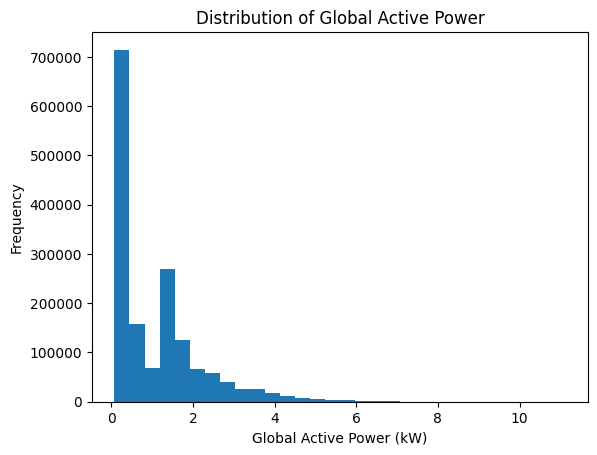

In [36]:
plt.hist(df['Global_active_power'], bins=30)
plt.title('Distribution of Global Active Power')
plt.xlabel('Global Active Power (kW)')
plt.ylabel('Frequency')
plt.show()

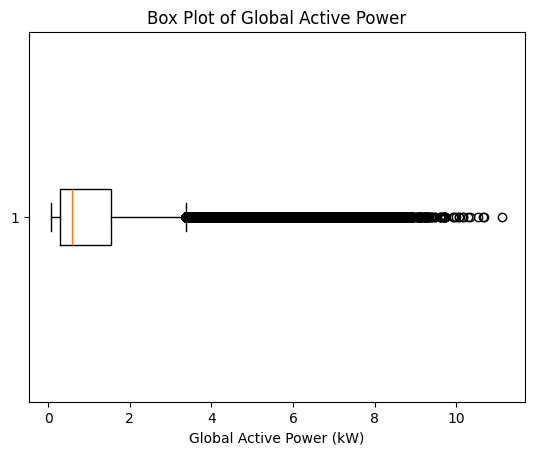

In [37]:
plt.boxplot(df['Global_active_power'].dropna(),vert=False)
plt.title('Box Plot of Global Active Power')
plt.xlabel('Global Active Power (kW)')
plt.show()

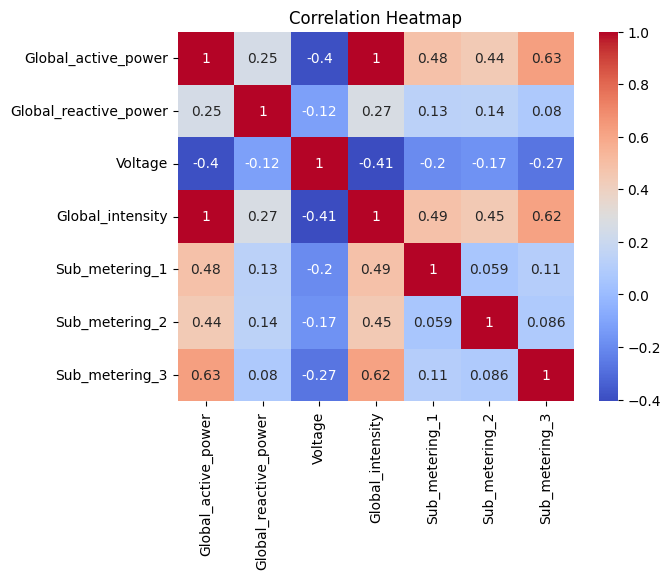

In [38]:
sns.heatmap(df.select_dtypes(include='number').corr(),annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

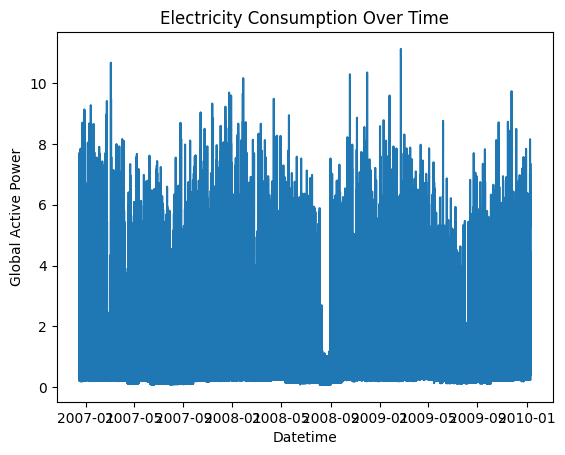

In [39]:
#electricity consumption over time
plt.plot(df['Datetime'], df['Global_active_power'])
plt.xlabel('Datetime')
plt.ylabel('Global Active Power')
plt.title('Electricity Consumption Over Time')
plt.show()

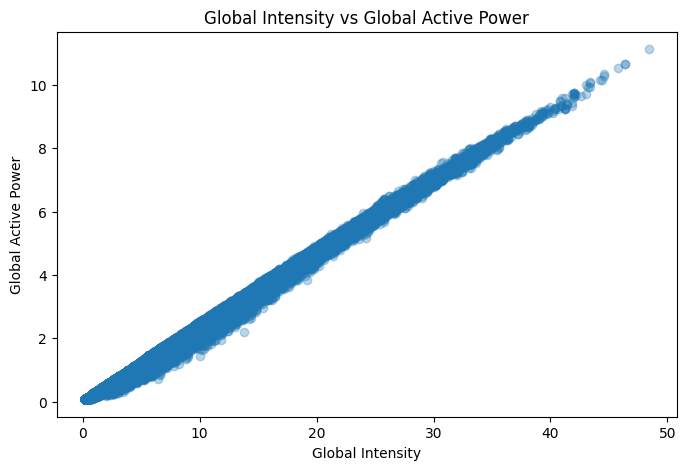

In [40]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Global_intensity'],df['Global_active_power'],alpha=0.3)
plt.xlabel('Global Intensity')
plt.ylabel('Global Active Power')
plt.title('Global Intensity vs Global Active Power')
plt.show()

Feature engineering — extract time features

In [41]:
df['Hour'] = df['Datetime'].dt.hour
df['Day'] = df['Datetime'].dt.day
df['Month'] = df['Datetime'].dt.month
df['DayOfWeek'] = df['Datetime'].dt.dayofweek

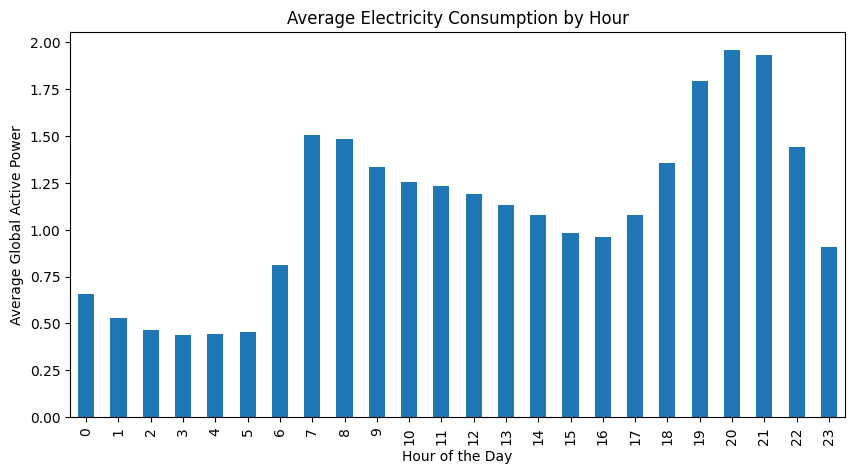

In [42]:
#Which hours of the day have higher or lower average electricity consumption
hourly_consumption = df.groupby('Hour')['Global_active_power'].mean()
hourly_consumption.plot(kind='bar', figsize=(10, 5))
plt.xlabel('Hour of the Day')
plt.ylabel('Average Global Active Power')
plt.title('Average Electricity Consumption by Hour')
plt.show()

In [43]:
X = df[['Global_reactive_power',
              'Voltage',
              'Global_intensity',
              'Sub_metering_1',
              'Sub_metering_2',
              'Sub_metering_3','Hour','Day','Month','DayOfWeek']]

y = df['Global_active_power']

In [44]:
print(X.shape)
print(y.shape)

(1605636, 10)
(1605636,)


In [45]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1284508, 10)
X_test: (321128, 10)
y_train: (1284508,)
y_test: (321128,)


In [46]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)
print("Linear Regression completed!")

Linear Regression completed!


In [47]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(random_state=42)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)
print("Decision Tree completed!")

Decision Tree completed!


In [48]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=30,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
print("Random Forest completed!")

Random Forest completed!


In [49]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
knn_predictions = knn_model.predict(X_test)

print("KNN Regression completed!")

KNN Regression completed!


In [50]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(name, actual, predicted):
    return {
        'Model': name,
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2 Score': r2_score(actual, predicted)
    }

In [51]:
results = pd.DataFrame([
    evaluate_model('Linear Regression', y_test, linear_predictions),
    evaluate_model('KNN Regression', y_test, knn_predictions),
    evaluate_model('Decision Tree', y_test, tree_predictions),
    evaluate_model('Random Forest', y_test, rf_predictions)
])

# Sort models by lowest RMSE
results = results.sort_values('RMSE').reset_index(drop=True)
display(results)

print("Best model based on RMSE:", results.loc[0, 'Model'])

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.020228,0.032501,0.998876
1,Linear Regression,0.025545,0.038922,0.998387
2,Decision Tree,0.027936,0.047180,0.997631
3,KNN Regression,0.102295,0.152035,0.975396


Best model based on RMSE: Random Forest


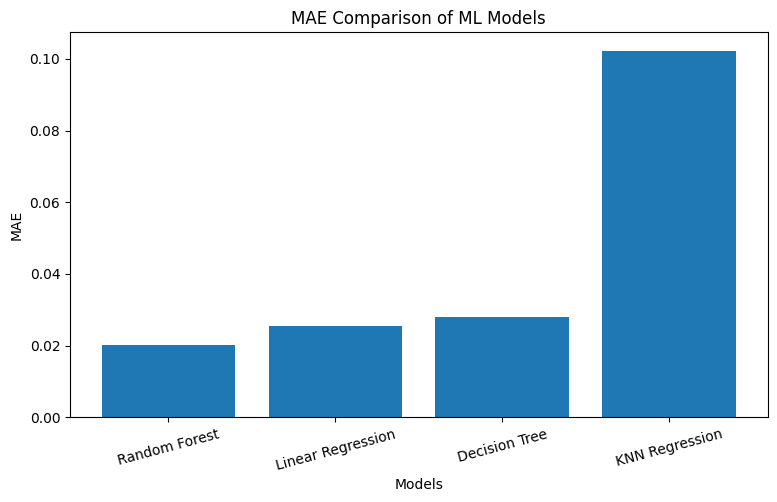

In [52]:
plt.figure(figsize=(9, 5))

plt.bar(results['Model'], results['MAE'])
plt.ylabel('MAE')
plt.xlabel('Models')
plt.title('MAE Comparison of ML Models')
plt.xticks(rotation=15)
plt.show()

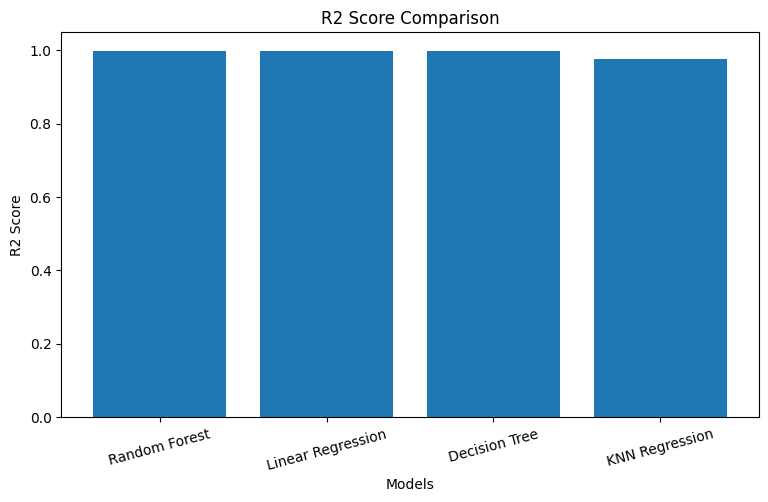

In [53]:
plt.figure(figsize=(9, 5))

plt.bar(results['Model'], results['R2 Score'])

plt.ylabel('R2 Score')
plt.xlabel('Models')
plt.title('R2 Score Comparison')
plt.xticks(rotation=15)

plt.show()

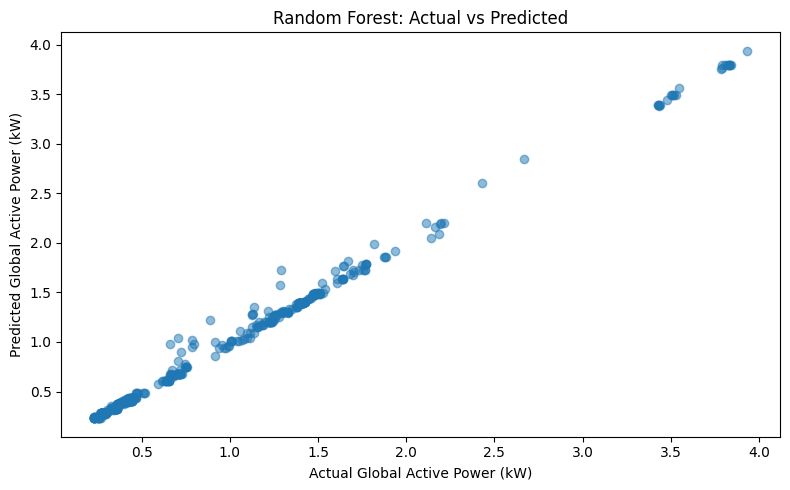

In [54]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test.iloc[:500], rf_predictions[:500], alpha=0.5)
plt.xlabel('Actual Global Active Power (kW)')
plt.ylabel('Predicted Global Active Power (kW)')
plt.title('Random Forest: Actual vs Predicted')
plt.tight_layout()
plt.show()

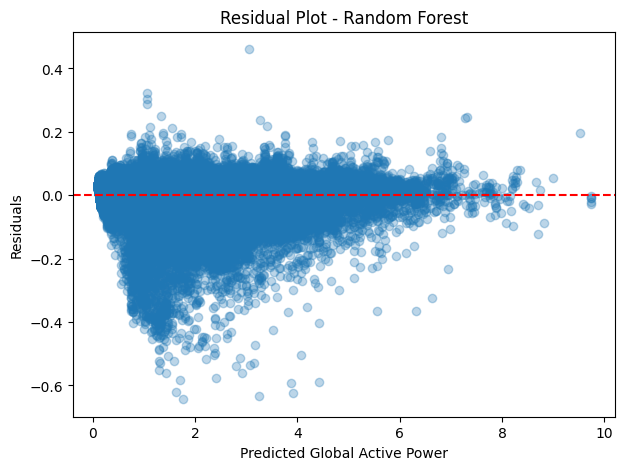

In [55]:
residuals = y_test - rf_predictions

plt.figure(figsize=(7, 5))

plt.scatter(
    rf_predictions,
    residuals,
    alpha=0.3
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel('Predicted Global Active Power')
plt.ylabel('Residuals')

plt.title('Residual Plot - Random Forest')

plt.show()

In [56]:
prediction_comparison = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': rf_predictions[:10]
})

display(prediction_comparison)

,Actual,Predicted
0,0.958,0.964643
1,1.072,1.018217
2,1.098,1.041746
3,1.112,1.041980
4,0.994,0.959859
5,0.446,0.408863
6,0.446,0.408863
7,0.444,0.408863
8,0.444,0.408863
9,0.442,0.408863


In [57]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,Global_intensity,0.999183
1,Voltage,0.000292
0,Global_reactive_power,0.000259
3,Sub_metering_1,0.000113
5,Sub_metering_3,0.000056
4,Sub_metering_2,0.000031
6,Hour,0.000027
8,Month,0.000023
7,Day,0.000013
9,DayOfWeek,0.000004


In [58]:
final_model = rf_model

print("Final Model Selected: Random Forest")

Final Model Selected: Random Forest


In [59]:
import pickle

with open('electricity_consumption_model.pkl', 'wb') as file:
    pickle.dump(final_model, file)

print("Model saved successfully!")

Model saved successfully!


In [60]:
with open('electricity_consumption_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [61]:
loaded_predictions = loaded_model.predict(X_test)

print("First 10 predictions:")

print(loaded_predictions[:10])

First 10 predictions:
[0.9646428  1.01821711 1.04174597 1.04197995 0.95985914 0.40886308
 0.40886308 0.40886308 0.40886308 0.40886308]


In [62]:
from google.colab import files
files.download('electricity_consumption_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>